# 2 · Partisan sorting (Törnberg 2022) on the realistic network – and with a chatbot in the loop

**Törnberg's model.** Each person has one fixed party (A or B) and $F=10$ cultural traits with $m=10$ possible values (what car you drive, where you eat, …). Repeatedly, a random person $i$ looks at their contacts. A share $\gamma$ of those contacts is swapped, *for this one conversation*, for random people from anywhere in the population: non-local interaction, Törnberg's stand-in for digital media. The person picks one contact $j$ with probability $\propto \text{sim}_{ij}^{\,h}$, where

$$\text{sim}_{ij}=\frac{c\,[\text{party}_i=\text{party}_j]+\#\text{shared traits}}{c+F},\qquad c=4,$$

and copies one trait on which they differ. **Sorting** $\psi$ = mean trait similarity within parties − between parties.

**Two "h"s.** Here $h$ is always Törnberg's *influence homophily* (how strongly people prefer to learn from similar others). Băbeanu's pair exponent $\lambda_i\lambda_j$ from notebook 1 is called the *sociability* exponent and plays no role in this notebook beyond having built the network.

**What this notebook does.**
1. Checks the simulation engine against Törnberg's published results on his own lattice (§2.1c).
2. Fixes how "a share $\gamma$ of contacts" is rounded for people with few contacts (§2.1b).
3. Runs the sorting model on the realistic network from notebook 1 and compares it with the lattice, with a shuffled network, across $h$, and across mean degree (§2.2).
4. Adds a personal chatbot as a third kind of conversation partner, at realistic levels of non-local interaction (§2.3).

Party is assigned at random, independently of community: every community contains both parties, as in Törnberg, so the offline communities are *cross-cut* by party.

**Two separate sets of traits.** The 8 features from notebook 1 (Băbeanu) only built the offline network. The 10 cultural traits here are new and start at random (Törnberg's clean sheet, as in all his networks).

In [1]:
import os
import time
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit, prange

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
os.makedirs('figures', exist_ok=True)


def load(path):
    """Load a network saved by notebook 1."""
    d = np.load(path)
    g = nx.Graph()
    g.add_nodes_from(range(int(d['n'])))
    g.add_edges_from(d['edges'])
    return g, d


G, d = load('data/network.npz')                 # the realistic network (mean degree ~14.5)
n = G.number_of_nodes()
comm = d['comm']
G10, _ = load('data/network_k10.npz')           # same people, lower mean degree
G7, _ = load('data/network_k7.npz')


def lattice(side):
    """Törnberg's baseline: a side x side torus, each person tied to their 8 neighbours (Moore neighbourhood)."""
    L = nx.Graph()
    for i in range(side):
        for j in range(side):
            for di in (-1, 0, 1):
                for dj in (-1, 0, 1):
                    if di or dj:
                        L.add_edge(i * side + j, ((i + di) % side) * side + (j + dj) % side)
    return L


LAT, LAT196 = lattice(32), lattice(14)

# same degrees as G, but ties shuffled: clustering and communities destroyed
RW = G.copy()
nx.double_edge_swap(RW, nswap=10 * G.number_of_edges(), max_tries=200 * G.number_of_edges(), seed=1)


def csr(g):
    """Neighbour lists in compressed form (indptr, indices) for the compiled engine."""
    A = nx.to_scipy_sparse_array(g, nodelist=range(g.number_of_nodes()), format='csr')
    return A.indptr.astype(np.int64), A.indices.astype(np.int64)


GRAPHS = {'lattice (Törnberg)': LAT,
          'feature-driven network': G,
          'degree-preserving rewiring': RW,
          'feature-driven, mean degree 10': G10,
          'feature-driven, mean degree 7': G7,
          'lattice 14×14 (Törnberg size)': LAT196}
NETS = {k: csr(g) for k, g in GRAPHS.items()}


def largest_component(g):
    return g.subgraph(max(nx.connected_components(g), key=len))


pd.DataFrame({k: {'people': g.number_of_nodes(),
                  'mean degree': 2 * g.number_of_edges() / g.number_of_nodes(),
                  'min degree': min(dict(g.degree()).values()),
                  'clustering': nx.average_clustering(g),
                  'path length': nx.average_shortest_path_length(largest_component(g))}
              for k, g in GRAPHS.items()}).T.round(2)

,people,mean degree,min degree,clustering,path length
lattice (Törnberg),1024.0,8.00,8.0,0.43,10.68
feature-driven network,1024.0,14.57,1.0,0.29,3.24
degree-preserving rewiring,1024.0,14.57,1.0,0.06,2.73
"feature-driven, mean degree 10",1024.0,9.15,0.0,0.32,3.84
"feature-driven, mean degree 7",1024.0,6.49,0.0,0.41,4.68
lattice 14×14 (Törnberg size),196.0,8.00,8.0,0.43,4.70


## 2.1 Simulation engine

A compiled (numba) re-implementation of Törnberg's `sorting_model.step`, run in parallel over replicates. One *sweep* = $n$ update attempts. It also contains the chatbot used in §2.3 (`mode` 0 = off) and a switch `sr` for how $\gamma\times$degree is rounded (§2.1b).

In [2]:
# ---- measures --------------------------------------------------------------------------------
@njit(cache=True)
def measures(flex, party, q):
    """Return (sorting psi, mean pairwise trait similarity, number of distinct cultures).
    psi = mean similarity within parties - mean similarity between parties."""
    n, F = flex.shape
    within = 0.0
    between = 0.0
    n_within = 0
    n_between = 0
    for i in range(n):
        for j in range(i + 1, n):
            s = 0
            for f in range(F):
                if flex[i, f] == flex[j, f]:
                    s += 1
            if party[i] == party[j]:
                within += s
                n_within += 1
            else:
                between += s
                n_between += 1
    # count distinct cultures by encoding each person's traits as one integer
    key = np.zeros(n, np.int64)
    for i in range(n):
        for f in range(F):
            key[i] = key[i] * q + flex[i, f]
    key.sort()
    distinct = 1
    for i in range(1, n):
        if key[i] != key[i - 1]:
            distinct += 1
    psi = within / n_within / F - between / n_between / F
    homogeneity = (within + between) / (n_within + n_between) / F
    return psi, homogeneity, distinct


# ---- the chatbot (section 2.3) ---------------------------------------------------------------
@njit(cache=True)
def chatbot_answers(flex, party, q, by_party):
    """The chatbot's answer on each trait: the majority value in the whole population (row 0),
    or, if by_party, the majority value within each party (row = party)."""
    n, F = flex.shape
    out = np.zeros((2, F), np.int64)
    for g in range(2):
        for f in range(F):
            counts = np.zeros(q, np.int64)
            for i in range(n):
                if (not by_party) or party[i] == g:
                    counts[flex[i, f]] += 1
            out[g, f] = np.argmax(counts)
    return out


# ---- one conversation ------------------------------------------------------------------------
@njit(cache=True)
def copy_one_trait(flex, i, source):
    """Person i adopts one randomly chosen trait on which they differ from `source`."""
    F = flex.shape[1]
    n_diff = 0
    for f in range(F):
        if flex[i, f] != source[f]:
            n_diff += 1
    if n_diff == 0:
        return
    r = np.random.randint(n_diff)
    t = 0
    for f in range(F):
        if flex[i, f] != source[f]:
            if t == r:
                flex[i, f] = source[f]
                return
            t += 1


@njit(cache=True)
def simulate(indptr, indices, flex, party, q, gamma, h, c, sweeps, alpha, mode, rec_every, sr):
    """Run the model, changing `flex` in place. Returns psi recorded every `rec_every` sweeps.
    gamma: share of contacts swapped for random strangers per conversation
    h:     influence homophily;  c: party bonus (sharing a party counts as c shared traits)
    alpha: probability a conversation is with the chatbot
    mode:  0 = no chatbot, 1 = aggregator, 2 = mirror
    sr:    1 = stochastic rounding of gamma*degree, 0 = Törnberg's int() rounding"""
    n, F = flex.shape
    rec = np.zeros(sweeps // rec_every + 1)
    rec[0] = measures(flex, party, q)[0]
    cand = np.zeros(n, np.int64)
    weights = np.zeros(n)
    answers = chatbot_answers(flex, party, q, mode == 2)

    for sw in range(1, sweeps + 1):
        if mode > 0:                                        # chatbot retrains every sweep
            answers = chatbot_answers(flex, party, q, mode == 2)

        for _ in range(n):                                  # one sweep = n conversations
            i = np.random.randint(n)

            # 1. talk to the chatbot instead of a person?
            if mode > 0 and np.random.random() < alpha:
                copy_one_trait(flex, i, answers[party[i] if mode == 2 else 0])
                continue

            # 2. candidate partners: i's contacts, with a share gamma swapped for random strangers
            deg = indptr[i + 1] - indptr[i]
            if deg == 0:
                continue
            for a in range(deg):
                cand[a] = indices[indptr[i] + a]
            n_strangers = int(gamma * deg)
            if sr == 1 and np.random.random() < gamma * deg - n_strangers:
                n_strangers += 1
            for a in range(n_strangers):
                b = a + np.random.randint(deg - a)
                cand[b] = cand[a]
                j = np.random.randint(n)
                while j == i:
                    j = np.random.randint(n)
                cand[a] = j

            # 3. weight each candidate by similarity^h (party counts as c shared traits)
            total = 0.0
            for a in range(deg):
                j = cand[a]
                s = 0
                for f in range(F):
                    if flex[i, f] == flex[j, f]:
                        s += 1
                weights[a] = ((s + (c if party[i] == party[j] else 0.0)) / (F + c)) ** h
                total += weights[a]
            if total <= 0:
                continue

            # 4. draw one partner and copy one of their traits
            r = np.random.random() * total
            a = 0
            acc = weights[0]
            while acc < r and a < deg - 1:
                a += 1
                acc += weights[a]
            copy_one_trait(flex, i, flex[cand[a]])

        if sw % rec_every == 0:
            rec[sw // rec_every] = measures(flex, party, q)[0]
    return rec


# ---- many runs in parallel -------------------------------------------------------------------
@njit(parallel=True, cache=True)
def batch(indptr, indices, n, F, q, gammas, hs, alphas, modes, seeds, c, sweeps, rec_every, flex_init, use_init, sr):
    """Run len(gammas) independent replicates in parallel, each from a random start.
    Returns (psi records, final homogeneity, final number of cultures)."""
    J = len(gammas)
    recs = np.zeros((J, sweeps // rec_every + 1))
    homog = np.zeros(J)
    distinct = np.zeros(J)
    for k in prange(J):
        np.random.seed(seeds[k])
        party = np.zeros(n, np.int64)
        flex = np.zeros((n, F), np.int64)
        for i in range(n):
            party[i] = np.random.randint(2)
            for f in range(F):
                flex[i, f] = flex_init[i, f] if use_init else np.random.randint(q)
        recs[k] = simulate(indptr, indices, flex, party, q, gammas[k], hs[k], c, sweeps,
                           alphas[k], modes[k], rec_every, sr)
        _, homog[k], distinct[k] = measures(flex, party, q)
    return recs, homog, distinct


# ---- convenience wrapper ---------------------------------------------------------------------
F_T, Q_T, C_ID = 10, 10, 4.0        # Törnberg: 10 traits x 10 values, party bonus c = 4
SWEEPS, REC = 3000, 250             # run length, and record psi every 250 sweeps


def experiment(net, gammas, h=8.0, alpha=0.0, mode=0, reps=16, seed0=0, sr=1, sweeps=SWEEPS):
    """Run `reps` replicates for each gamma on network `net`. Returns one row per run, and the psi records."""
    ip, ix = NETS[net]
    n_ = len(ip) - 1
    g = np.repeat(np.asarray(gammas, float), reps)
    J = len(g)
    recs, homog, uniq = batch(ip, ix, n_, F_T, Q_T, g, np.full(J, float(h)), np.full(J, float(alpha)),
                              np.full(J, mode, np.int64), seed0 + np.arange(J), C_ID, sweeps, min(REC, sweeps),
                              np.zeros((n_, F_T), np.int64), False, sr)
    runs = pd.DataFrame({'net': net, 'gamma': g, 'h': h, 'alpha': alpha, 'mode': mode,
                         'psi': recs[:, -1], 'homogeneity': homog, 'cultures': uniq})
    return runs, recs

## 2.1b How non-local interaction works – and a rounding problem

**No links are added.** The network never changes. In each conversation a person's contact list is copied, and $\lfloor\gamma k\rfloor$ of its $k$ entries are swapped for people drawn uniformly at random from the whole population. The stranger is used for that one conversation only. This follows Törnberg's code exactly.

**The rounding problem.** Törnberg's code rounds $\gamma k$ *down*. On his lattice everyone has $k=8$, so the effective share of strangers is $\lfloor 8\gamma\rfloor/8$: a mild step function. On a heavy-tailed network many people have 4–6 contacts, and for them $\lfloor\gamma k\rfloor=0$ until $\gamma$ is large. They then never meet a stranger at all.

In [3]:
# with Törnberg's rounding, how many people never meet a stranger?
rows = []
for net in ('lattice (Törnberg)', 'feature-driven network', 'feature-driven, mean degree 7'):
    k = np.array([dd for _, dd in GRAPHS[net].degree()])
    for g in (0.1, 0.2, 0.3, 0.5):
        n_strangers = np.floor(g * k)
        with np.errstate(invalid='ignore'):           # a few people in the sparse network have no ties
            share = (n_strangers / k).mean()
        rows.append({'network': net, 'gamma': g,
                     'share of people who never meet a stranger': (n_strangers == 0).mean(),
                     'average effective share of strangers': share})
pd.DataFrame(rows).pivot(index='gamma', columns='network').round(2)

/var/folders/d8/l6dhklj95tqd2lspd7z3s0nr0000gn/T/ipykernel_86730/1776496919.py:7: RuntimeWarning: invalid value encountered in divide
  'average effective share of strangers': (nr / k).mean()})


share of people who never meet a stranger  \
network                    feature-driven network   
gamma                                               
0.1                                          0.46   
0.2                                          0.06   
0.3                                          0.02   
0.5                                          0.00   

                                                          \
network feature-driven, mean degree 7 lattice (Törnberg)   
gamma                                                      
0.1                              0.86                1.0   
0.2                              0.54                0.0   
0.3                              0.36                0.0   
0.5                              0.06                0.0   

        average effective share of strangers                                \
network               feature-driven network feature-driven, mean degree 7   
gamma                                                                        
0.1                                     0.04                           NaN   
0.2                                     0.16                           NaN   
0.3                                     0.25                           NaN   
0.5                                     0.47                           NaN   

                            
network lattice (Törnberg)  
gamma                       
0.1                   0.00  
0.2                   0.12  
0.3                   0.25  
0.5                   0.50

**Fix used from here on (`sr=1`).** Round $\gamma k$ *stochastically*: up with probability equal to its fractional part. Every person then meets strangers in exactly a share $\gamma$ of their contacts on average, whatever their degree. The replication in §2.1c uses Törnberg's original rounding (`sr=0`) to stay faithful to the paper.

## 2.1c Does the engine reproduce Törnberg's results?

Same set-up as his Fig. 2: a 14×14 lattice (196 people), $c=4$, $m=10$, $n=10$ traits, 500,000 steps (≈2,550 sweeps), $h\in\{1,4,8\}$, his rounding.

528 runs in 26s


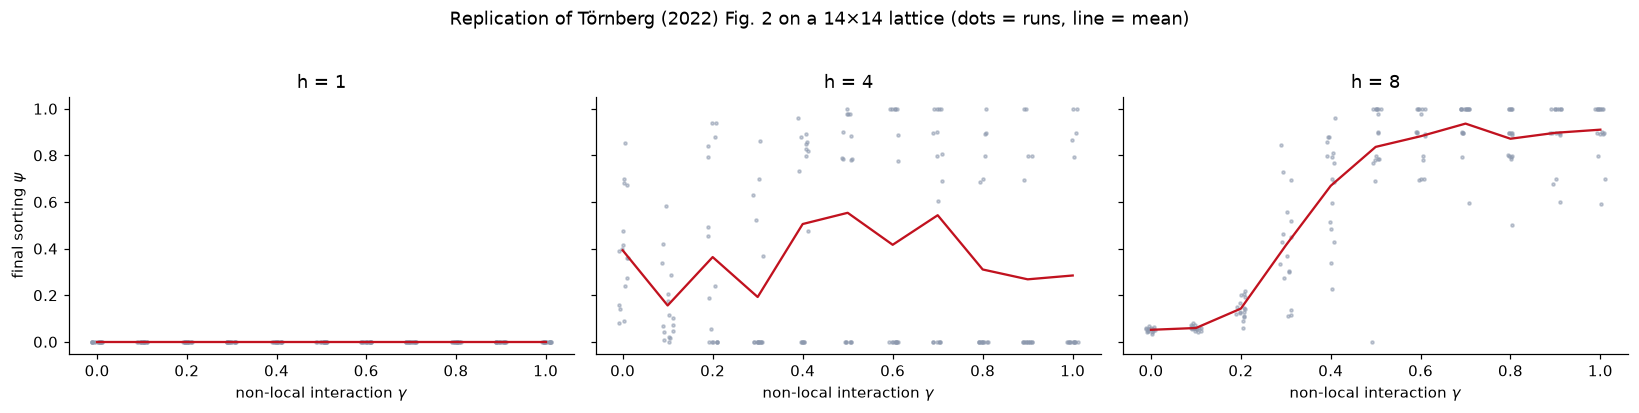

mean             sorted_share            
h        1     4     8            1     4     8
gamma                                          
0.0    0.0  0.39  0.05          0.0  0.62  0.00
0.1    0.0  0.16  0.06          0.0  0.19  0.00
0.2    0.0  0.36  0.14          0.0  0.44  0.00
0.3    0.0  0.19  0.41          0.0  0.31  0.69
0.4    0.0  0.51  0.67          0.0  0.62  0.94
0.5    0.0  0.55  0.84          0.0  0.62  0.94
0.6    0.0  0.42  0.88          0.0  0.44  1.00
0.7    0.0  0.54  0.94          0.0  0.62  1.00
0.8    0.0  0.31  0.87          0.0  0.38  1.00
0.9    0.0  0.27  0.90          0.0  0.31  1.00
1.0    0.0  0.28  0.91          0.0  0.31  1.00

In [4]:
gammas = np.linspace(0, 1, 11)
t0 = time.time()
REP = []
for h in (1, 4, 8):
    df, _ = experiment('lattice 14×14 (Törnberg size)', gammas, h=h, reps=16, seed0=7000 + 100 * h, sr=0, sweeps=2550)
    REP.append(df)
REP = pd.concat(REP)
print(f'{len(REP)} runs in {time.time() - t0:.0f}s')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
jit = np.random.default_rng(0)                         # horizontal jitter for the dots
for a, h in zip(ax, (1, 4, 8)):
    s = REP[REP.h == h]
    a.plot(s.gamma + jit.uniform(-.012, .012, len(s)), s.psi, '.', ms=4, alpha=.5, color='#8d99ae')
    a.plot(gammas, s.groupby('gamma').psi.mean(), '-', color='#c1121f')
    a.set(title=f'h = {h}', xlabel='non-local interaction $\\gamma$')
ax[0].set_ylabel('final sorting $\\psi$')
plt.suptitle("Replication of Törnberg (2022) Fig. 2 on a 14×14 lattice (dots = runs, line = mean)", y=1.03)
plt.tight_layout()
plt.savefig('figures/02a_replication.png', dpi=150, bbox_inches='tight')
plt.show()

# mean psi and share of runs that end sorted (psi > 0.3)
REP.groupby(['h', 'gamma']).psi.agg(mean='mean', sorted_share=lambda s: (s > 0.3).mean()).unstack(0).round(2)

**Result: the engine reproduces the paper.** $h=1$: no sorting at any $\gamma$ (his Fig. 2A). $h=8$: $\psi\approx0.05$ up to $\gamma=0.2$, then a sharp rise; from $\gamma=0.4$ almost every run ends sorted (his Fig. 2C). $h=4$: runs end either near 0 or near 0.8–1, roughly half each, across most of the range: the bistability he reports (his Fig. 2B). On larger networks (1,024 people, §2.2) the rise at $h=8$ comes later, and $h=4$ sorts less often: the outcome depends on system size.

## 2.2 Does non-local interaction drive sorting on the realistic network?

In [5]:
t0 = time.time()
runs = []
# h = 8 on five networks
for k, net in enumerate(('lattice (Törnberg)', 'feature-driven network', 'degree-preserving rewiring',
                         'feature-driven, mean degree 10', 'feature-driven, mean degree 7')):
    df, _ = experiment(net, gammas, h=8, reps=16, seed0=1000 * k)
    runs.append(df)
# h = 1 and h = 4 on the realistic network
for h in (1, 4):
    df, _ = experiment('feature-driven network', gammas, h=h, reps=16, seed0=50000 + 1000 * h)
    runs.append(df)

R = pd.concat(runs, ignore_index=True)
R.to_csv('data/sorting_runs.csv', index=False)
print(f'{len(R)} runs in {time.time() - t0:.0f}s')
R[R.h == 8].groupby(['net', 'gamma']).psi.agg(mean='mean', sorted_share=lambda s: (s > 0.3).mean()).unstack(0).round(2)

1232 runs in 347s


mean                         \
net   degree-preserving rewiring feature-driven network   
gamma                                                     
0.0                         0.09                   0.05   
0.1                         0.56                   0.14   
0.2                         0.67                   0.21   
0.3                         0.80                   0.30   
0.4                         0.81                   0.50   
0.5                         0.86                   0.64   
0.6                         0.89                   0.83   
0.7                         0.82                   0.85   
0.8                         0.85                   0.84   
0.9                         0.87                   0.78   
1.0                         0.79                   0.85   

                                                                    \
net   feature-driven, mean degree 10 feature-driven, mean degree 7   
gamma                                                                
0.0                             0.03                          0.02   
0.1                             0.08                          0.03   
0.2                             0.07                          0.02   
0.3                             0.16                          0.01   
0.4                             0.13                          0.00   
0.5                             0.23                          0.01   
0.6                             0.37                         -0.00   
0.7                             0.36                         -0.00   
0.8                             0.06                         -0.00   
0.9                            -0.00                          0.00   
1.0                             0.00                          0.00   

                                       sorted_share                         \
net   lattice (Törnberg) degree-preserving rewiring feature-driven network   
gamma                                                                        
0.0                 0.01                       0.00                   0.00   
0.1                 0.03                       0.94                   0.00   
0.2                 0.04                       1.00                   0.12   
0.3                 0.07                       0.94                   0.44   
0.4                 0.28                       1.00                   0.88   
0.5                 0.41                       1.00                   1.00   
0.6                 0.75                       1.00                   1.00   
0.7                 0.85                       1.00                   1.00   
0.8                 0.84                       1.00                   1.00   
0.9                 0.82                       1.00                   0.94   
1.0                 0.81                       1.00                   1.00   

                                                                    \
net   feature-driven, mean degree 10 feature-driven, mean degree 7   
gamma                                                                
0.0                             0.00                           0.0   
0.1                             0.00                           0.0   
0.2                             0.00                           0.0   
0.3                             0.06                           0.0   
0.4                             0.06                           0.0   
0.5                             0.38                           0.0   
0.6                             0.56                           0.0   
0.7                             0.69                           0.0   
0.8                             0.12                           0.0   
0.9                             0.00                           0.0   
1.0                             0.00                           0.0   

                          
net   lattice (Törnberg)  
gamma                     
0.0                 0.00  
0.1                 0.00  
0.2        

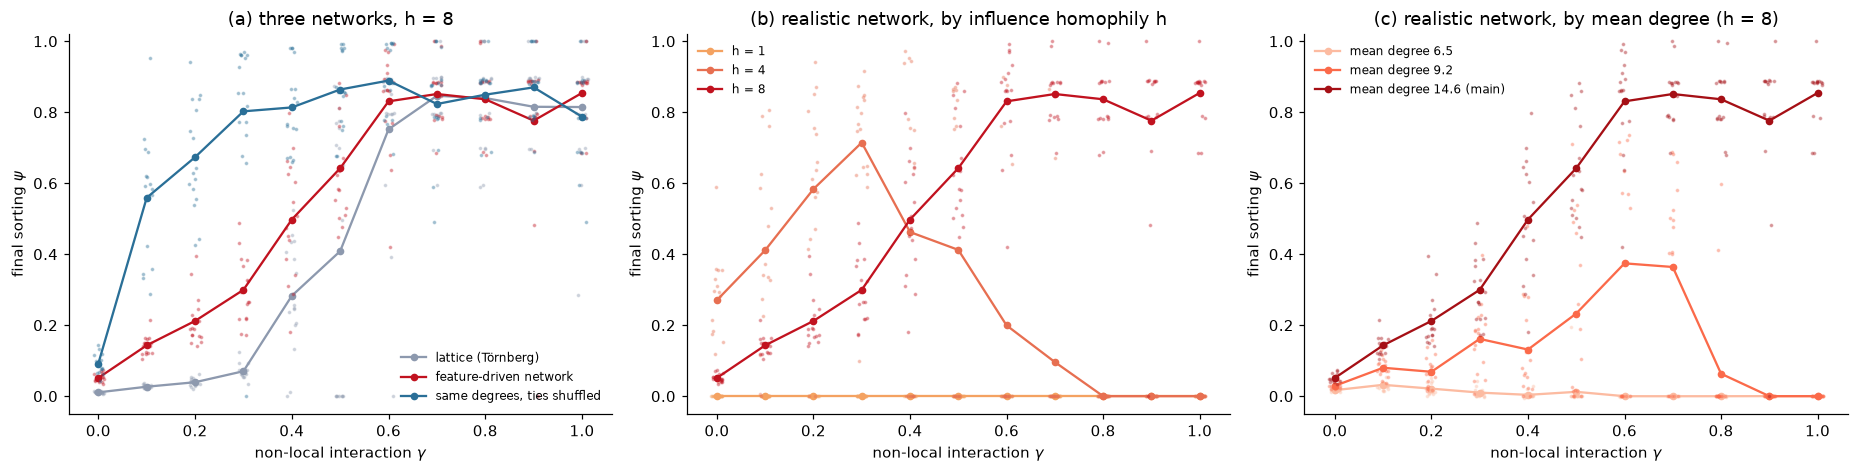

In [6]:
def panel(a, nets, colours, title, labels, hsel=8):
    """Final psi against gamma: dots = runs, line = mean. `nets` items are a network name or (h, name)."""
    for net, c_, lab in zip(nets, colours, labels):
        hh, nn = net if isinstance(net, tuple) else (hsel, net)
        s = R[(R.net == nn) & (R.h == hh)]
        a.plot(s.gamma + jit.uniform(-.012, .012, len(s)), s.psi, '.', ms=3, alpha=.3, color=c_)
        a.plot(gammas, s.groupby('gamma').psi.mean(), '-o', ms=4, color=c_, label=lab)
    a.set(xlabel='non-local interaction $\\gamma$', ylabel='final sorting $\\psi$', title=title, ylim=(-0.05, 1.02))
    a.legend(frameon=False, fontsize=8)


def mean_degree_label(net):
    label = f'mean degree {2 * GRAPHS[net].number_of_edges() / n:.1f}'
    return label + (' (main)' if net == 'feature-driven network' else '')


fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
panel(ax[0], ('lattice (Törnberg)', 'feature-driven network', 'degree-preserving rewiring'),
      ('#8d99ae', '#c1121f', '#2a6f97'), '(a) three networks, h = 8',
      ('lattice (Törnberg)', 'feature-driven network', 'same degrees, ties shuffled'))
panel(ax[1], ((1, 'feature-driven network'), (4, 'feature-driven network'), (8, 'feature-driven network')),
      ('#f4a261', '#e76f51', '#c1121f'), '(b) realistic network, by influence homophily h',
      ('h = 1', 'h = 4', 'h = 8'))
by_degree = ('feature-driven, mean degree 7', 'feature-driven, mean degree 10', 'feature-driven network')
panel(ax[2], by_degree, ('#fcbba1', '#fb6a4a', '#a50f15'), '(c) realistic network, by mean degree (h = 8)',
      tuple(mean_degree_label(k) for k in by_degree))
plt.tight_layout()
plt.savefig('figures/02_sorting_vs_gamma.png', dpi=160, bbox_inches='tight')
plt.show()

**How to read the three panels.** Each dot is one run, the line is the average. x = share of each person's conversations that are with random strangers ($\gamma$); y = how sorted the society ends up ($\psi$: 0 = culture has nothing to do with party, about 0.8 = each party has its own culture). (a) Törnberg's 32×32 grid (grey), the realistic network (red) and the same friend counts with ties shuffled at random (blue). (b) The realistic network at three strengths of influence homophily $h$. (c) The same people and feature table, fitted to three different mean degrees.

### Why do people with few contacts matter? A check on regular networks

With only strangers ($\gamma=1$) the network matters only through *how many* conversation partners each person has. Random regular networks (everyone has exactly $k$ contacts) isolate that effect.

In [7]:
# random regular networks: everyone has exactly k contacts, only strangers (gamma = 1)
chk = []
for k in (4, 6, 8, 16):
    name = f'regular, k={k}'
    GRAPHS[name] = nx.random_regular_graph(k, n, seed=1)
    NETS[name] = csr(GRAPHS[name])
    df, _ = experiment(name, [1.0], h=8, reps=12, seed0=300000 + k)
    chk.append(df)
chk = pd.concat(chk)

for net in ('feature-driven, mean degree 7', 'feature-driven, mean degree 10', 'feature-driven network'):
    kk = np.array([dd for _, dd in GRAPHS[net].degree()])
    print(f'{net}: share of people with ≤ 6 contacts = {(kk <= 6).mean():.2f}')
chk.groupby('net').agg(mean_psi=('psi', 'mean'), sorted_share=('psi', lambda s: (s > 0.3).mean()),
                       cultures=('cultures', 'mean')).round(2)

feature-driven, mean degree 7: share of people with ≤ 6 contacts = 0.73
feature-driven, mean degree 10: share of people with ≤ 6 contacts = 0.53
feature-driven network: share of people with ≤ 6 contacts = 0.20


,mean_psi,sorted_share,cultures
net,,,
"regular, k=16",0.92,1.00,2.00
"regular, k=4",0.00,0.00,1.00
"regular, k=6",0.45,0.75,11.33
"regular, k=8",0.82,1.00,7.42


## 2.2b What the end states look like

Shape = party, colour = cultural configuration (all 10 traits). The 10 most common shared configurations get a colour; everything else is light grey. The bars underneath show, for each party, what share of its members holds each culture: if each bar is mostly one colour and the two colours differ, culture follows party.

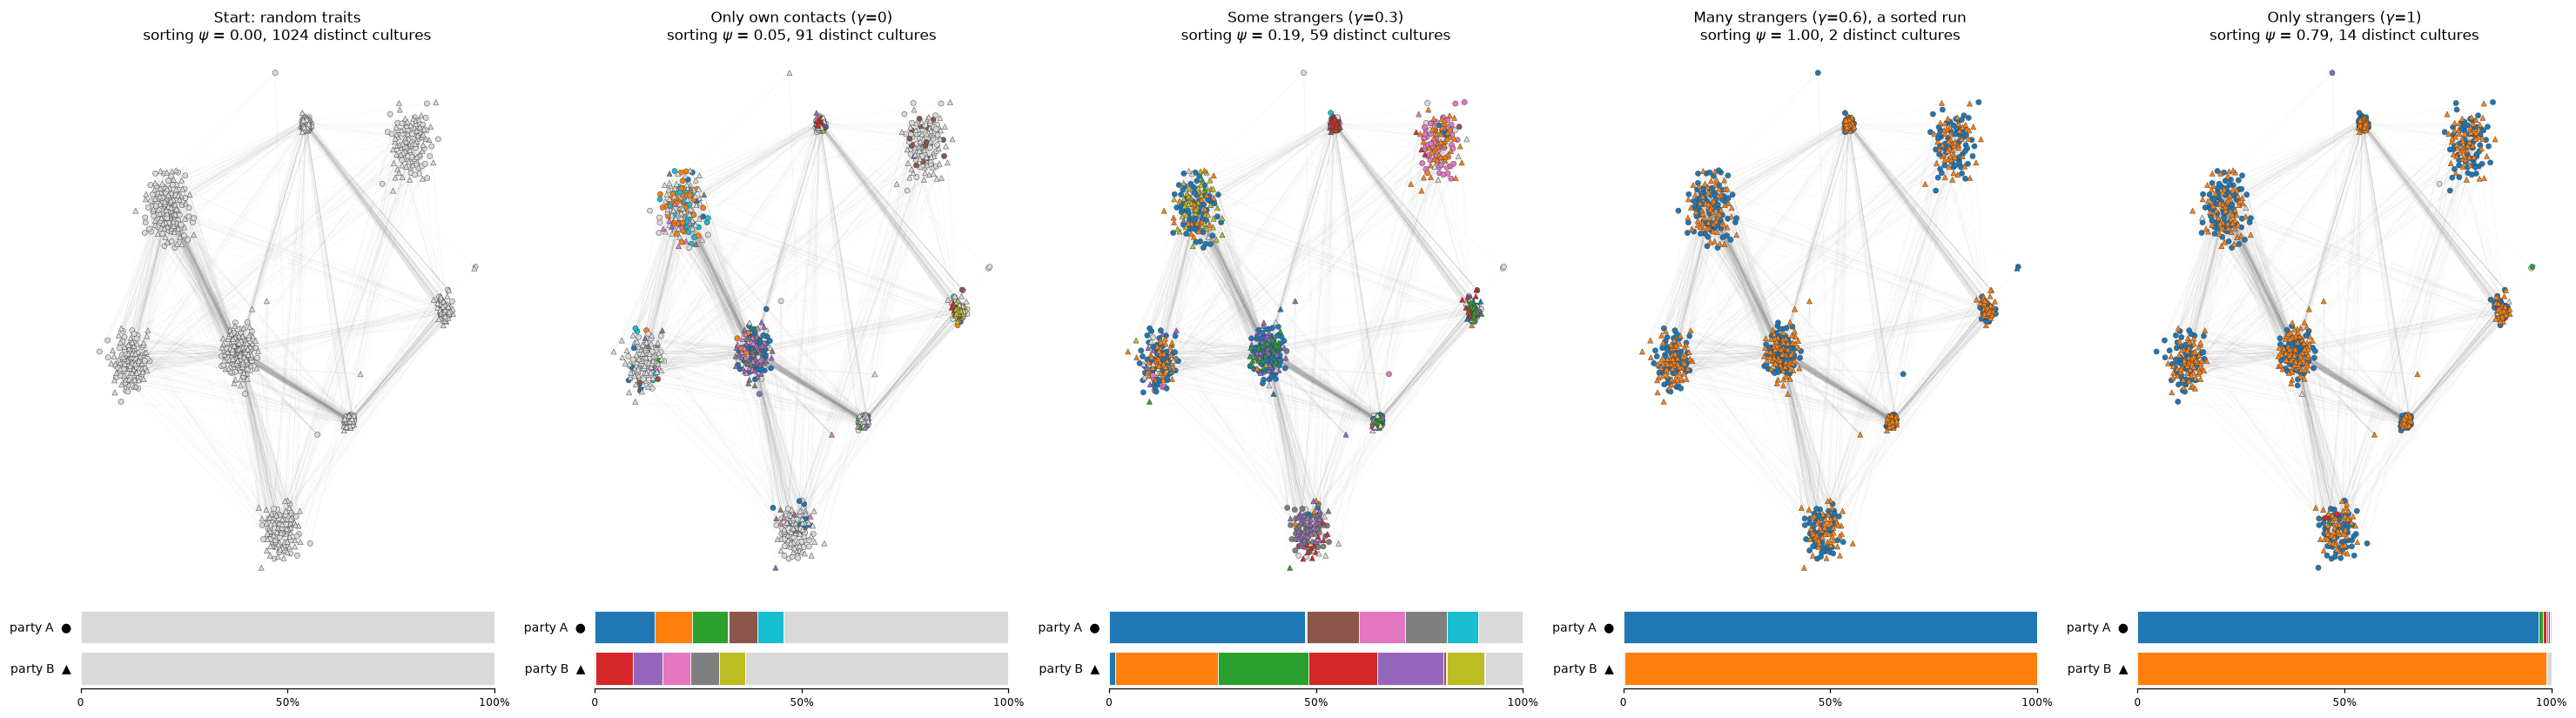

In [8]:
@njit(cache=True)
def run_one(indptr, indices, flex, party, q, gamma, h, c, sweeps, alpha, mode, seed, sr):
    """A single run that changes `flex` in place (to draw end states)."""
    np.random.seed(seed)
    simulate(indptr, indices, flex, party, q, gamma, h, c, sweeps, alpha, mode, sweeps, sr)


pos = np.load('data/layout_community.npy')         # community layout from notebook 1
ip, ix = NETS['feature-driven network']
EDGES = np.array(G.edges())


def end_state(gamma, alpha=0.0, mode=0, seed=0, want=None, sweeps=SWEEPS):
    """Run on the realistic network from a random start. If `want` (a test on psi) is given,
    try seeds until a run passes it, to show a typical sorted or unsorted outcome."""
    for sd in range(seed, seed + 30):
        r = np.random.default_rng(sd)
        party = r.integers(0, 2, n).astype(np.int64)
        flex = r.integers(0, Q_T, (n, F_T)).astype(np.int64)
        if sweeps > 0:
            run_one(ip, ix, flex, party, Q_T, gamma, 8.0, C_ID, sweeps, alpha, mode, sd, 1)
        psi, homog, uniq = measures(flex, party, Q_T)
        if want is None or want(psi):
            return party, flex, psi, uniq
    return party, flex, psi, uniq


def draw_state(ax, axb, party, flex, title):
    """Network: shape = party, colour = culture (10 most common shared cultures; grey = any other).
    Bars below: share of each party holding each culture."""
    keys = [tuple(f) for f in flex]
    counts = pd.Series(keys).value_counts()
    top = [k for k, c in counts.items() if c > 1][:10]
    cmap = {k: plt.cm.tab10(i) for i, k in enumerate(top)}
    grey = (0.85, 0.85, 0.85, 1)
    colours = np.array([cmap.get(k, grey) for k in keys])

    ax.plot(pos[EDGES.T, 0], pos[EDGES.T, 1], color='0.5', lw=0.2, alpha=0.12, zorder=1)
    for p, marker in ((0, 'o'), (1, '^')):
        m = party == p
        ax.scatter(pos[m, 0], pos[m, 1], c=colours[m], marker=marker, s=16, edgecolors='0.25', linewidths=0.3, zorder=2)
    ax.set_title(title, fontsize=11)
    ax.axis('off')

    for row, p in enumerate((0, 1)):
        member_keys = [k for k, pp in zip(keys, party) if pp == p]
        left = 0.0
        for k in top + ['other']:
            share = np.mean([kk == k for kk in member_keys]) if k != 'other' else np.mean([kk not in cmap for kk in member_keys])
            axb.barh(row, share, left=left, color=cmap.get(k, grey) if k != 'other' else grey, edgecolor='white', lw=0.5)
            left += share
    axb.set_yticks([0, 1])
    axb.set_yticklabels(['party A  ●', 'party B  ▲'], fontsize=9)
    axb.set_xlim(0, 1)
    axb.invert_yaxis()
    axb.set_xticks([0, 0.5, 1])
    axb.set_xticklabels(['0', '50%', '100%'], fontsize=8)
    for side in ('top', 'right', 'left'):
        axb.spines[side].set_visible(False)
    axb.tick_params(left=False)


def cultures_word(u):
    return f'{u} distinct culture' + ('' if u == 1 else 's')


STATES = [('Start: random traits', end_state(0.0, sweeps=0)),
          ('Only own contacts ($\\gamma$=0)', end_state(0.0, seed=1)),
          ('Some strangers ($\\gamma$=0.3)', end_state(0.3, seed=5)),
          ('Many strangers ($\\gamma$=0.6), a sorted run', end_state(0.6, seed=2, want=lambda p: p > 0.5)),
          ('Only strangers ($\\gamma$=1)', end_state(1.0, seed=3))]

fig, ax = plt.subplots(2, 5, figsize=(27, 7.6), gridspec_kw={'height_ratios': [6, 0.9]})
for k, (title, (party, flex, psi, uniq)) in enumerate(STATES):
    draw_state(ax[0, k], ax[1, k], party, flex, f'{title}\nsorting $\\psi$ = {abs(psi):.2f}, {cultures_word(uniq)}')
plt.tight_layout()
plt.savefig('figures/02b_end_states.png', dpi=130, bbox_inches='tight')
plt.show()

**How to read it.** Start: everyone has their own random culture, so everything is grey. Only own contacts: small same-party groups inside each community settle on a local culture; each party is split into many cultures that change from place to place, so a fellow partisan elsewhere is no more like you than an opponent ($\psi\approx0$, Törnberg's "local differences cancel out"). With more strangers, people can pick fellow partisans from anywhere as models, and each party converges on one culture across the whole network: each bar becomes mostly one colour, different per party. That is partisan sorting.

### Findings (§2.2)

* **Yes, more contact with strangers means more sorting on the realistic network, as in Törnberg.** With a mean of 14.6 contacts, $\psi$ goes from 0.05 at $\gamma=0$ to 0.50 at $\gamma=0.4$ and about 0.85 from $\gamma=0.6$. The share of runs that end sorted is 44 % at $\gamma=0.3$, 88 % at 0.4 and 100 % from 0.5.
* **Communities slow sorting, short paths speed it up.** With the ties shuffled (same degrees, no communities, clustering 0.06), 94 % of runs are sorted already at $\gamma=0.1$. Tight communities keep local cultures alive longer, as Törnberg found for clique-rich networks. Compared with the grid (41 % sorted at $\gamma=0.5$), the realistic network sorts earlier, because hubs and short paths spread party cultures faster.
* **The mean degree matters most.** At mean degree 9.2, sorting peaks at $\psi\approx0.37$ ($\gamma=0.6$–0.7) and collapses to 0 for $\gamma\ge0.9$. At 6.5 there is no sorting at any $\gamma$. The regular-network check shows why: with only 4 conversation partners nothing sorts even at $\gamma=1$, with 6 three quarters of runs sort, and with 8 or more all do. In the three networks, 73 %, 53 % and 20 % of people have 6 or fewer contacts. My reading, not tested directly: a person with very few partners often finds no fellow partisan among them, copies from the other side, and so ties the two parties' cultures together.
* **Influence homophily.** $h=1$: no sorting. $h=4$: sorting at moderate $\gamma$ (peak $\psi=0.71$ at $\gamma=0.3$), but one shared culture once $\gamma\ge0.8$. Strong homophily ($h=8$) is needed for sorting to survive heavy contact with strangers.

**Caveats.** 16 runs per point; outcomes are bistable, so means mix sorted and unsorted runs (shares of sorted runs are in the table). One network realisation; the network is static.

## 2.3 Extension: a personal chatbot as a new kind of conversation partner

The setting is people talking to *their own* chatbot assistant: a private conversation with something they know is a machine, not an ambiguous account in a public online space. So the chatbot is modelled as an outside actor of its own kind (sui generis), not as one more person in the network.

* With probability $\alpha$ a conversation is with the chatbot instead of a person, and the person copies one trait from its answer. There is no homophily filter, because people do not treat their assistant as an out-group member.
* **Aggregator**: answers with the current majority value of each trait in the *whole population*, one voice for everyone.
* **Mirror**: answers with the majority value *within the user's own party*. It is personalised and sycophantic: it infers who you are and tells you what your side thinks.
* The chatbot's answers are recomputed every sweep, so it keeps up with the population it learns from.

**Realistic background level of non-local interaction.** Chatbots arrive in societies that already use social media, so they are tested at $\gamma\in\{0.2,0.3,0.4\}$, not at $\gamma=0$. There is no direct measurement of "share of everyday conversations that are with strangers". The evidence points to a substantial minority:

* most political and cultural talk still happens face-to-face, and people are more comfortable there (Pew 2019);
* social media is mostly used to keep up with existing offline contacts rather than to meet strangers (Lampe, Ellison & Steinfield 2007);
* but it does expose people to weak ties and to distant others' views, including through non-political posts (Settle 2018; Bakshy, Messing & Adamic 2015).

In this model $\gamma$ means *uniformly random* strangers, the most extreme kind of non-local contact, so a realistic value should sit below the raw share of online interaction. On the realistic network, $\gamma=0.2$–$0.4$ is the range where society is partly sorted (§2.2), which is where a new influence can tip it either way.

In [9]:
alphas = [0, 0.001, 0.003, 0.01, 0.03, 0.1]       # share of conversations with the chatbot
GAMS = (0.2, 0.3, 0.4)                             # realistic background levels of contact with strangers

t0 = time.time()
L = []
for mode, name in ((1, 'aggregator'), (2, 'mirror')):
    for gam in GAMS:
        for a in alphas:
            df, _ = experiment('feature-driven network', [gam], h=8, alpha=a, mode=mode if a > 0 else 0, reps=12,
                               seed0=200000 + int(1e4 * a) + 1000 * mode + int(100 * gam))
            df['llm'] = name
            df['alpha'] = a
            L.append(df)
L = pd.concat(L, ignore_index=True)
L.to_csv('data/llm_runs.csv', index=False)
print(f'{len(L)} runs in {time.time() - t0:.0f}s')
L.groupby(['llm', 'gamma', 'alpha'])[['psi', 'homogeneity', 'cultures']].mean().round(2).unstack(1)

432 runs in 135s


psi             homogeneity             cultures         \
gamma              0.2   0.3   0.4         0.2   0.3   0.4      0.2    0.3   
llm        alpha                                                             
aggregator 0.000  0.26  0.31  0.41        0.27  0.31  0.37    37.75  40.50   
           0.001  0.24  0.40  0.47        0.33  0.37  0.37    33.00  29.75   
           0.003  0.21  0.38  0.44        0.37  0.41  0.49    35.92  34.00   
           0.010  0.17  0.13  0.38        0.77  0.81  0.66    10.83   9.92   
           0.030  0.00  0.00  0.00        1.00  1.00  1.00     1.00   1.00   
           0.100  0.00  0.00  0.00        1.00  1.00  1.00     1.00   1.00   
mirror     0.000  0.24  0.36  0.45        0.24  0.33  0.37    36.67  34.33   
           0.001  0.28  0.43  0.58        0.29  0.34  0.41    34.58  34.17   
           0.003  0.48  0.54  0.57        0.39  0.40  0.45    25.67  28.83   
           0.010  0.79  0.79  0.74        0.54  0.54  0.56     8.00   8.67   
           0.030  0.83  0.89  0.87        0.57  0.53  0.55     7.00   6.08   
           0.100  0.89  0.87  0.89        0.54  0.55  0.55     5.67   7.50   

                         
gamma               0.4  
llm        alpha         
aggregator 0.000  42.08  
           0.001  35.75  
           0.003  24.42  
           0.010  17.17  
           0.030   1.00  
           0.100   1.00  
mirror     0.000  37.08  
           0.001  26.08  
           0.003  23.58  
           0.010  13.25  
           0.030   7.83  
           0.100   5.92

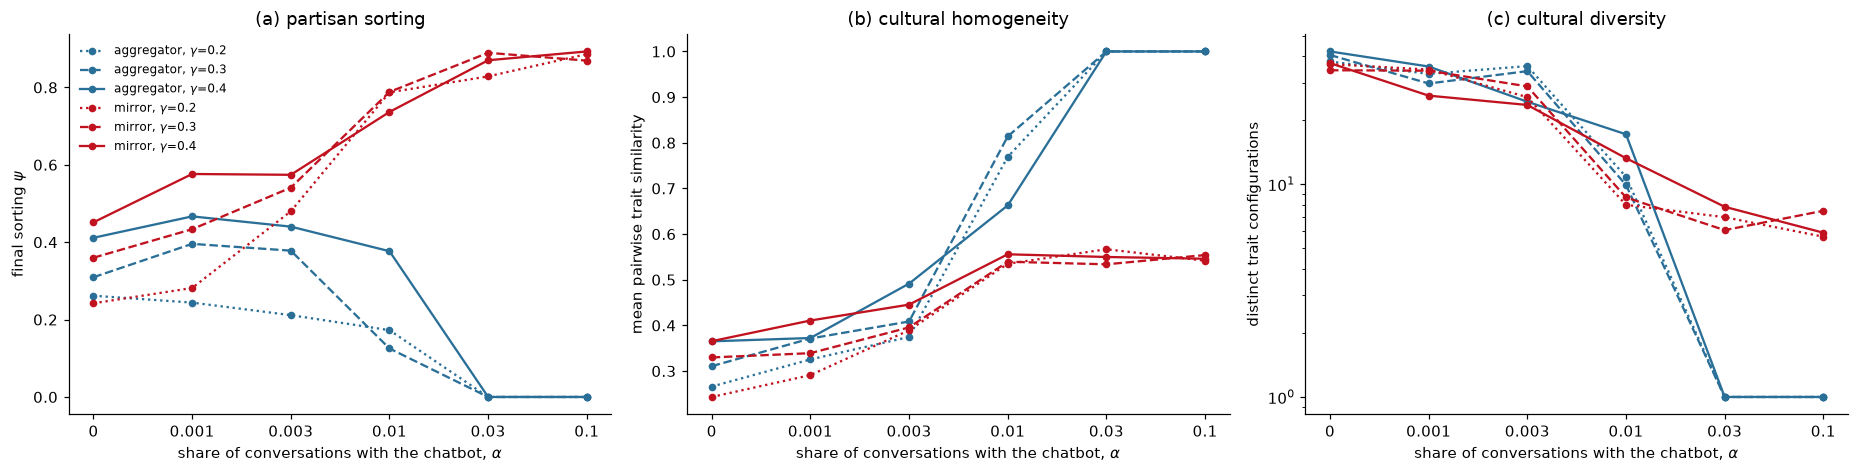

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
xs = np.arange(len(alphas))
for name, colour in (('aggregator', '#2a6f97'), ('mirror', '#c1121f')):
    for gam, style in zip(GAMS, (':', '--', '-')):
        s = L[(L.llm == name) & (L.gamma == gam)].groupby('alpha')[['psi', 'homogeneity', 'cultures']].mean()
        for k, col in enumerate(('psi', 'homogeneity', 'cultures')):
            ax[k].plot(xs, s[col].values, style, marker='o', ms=4, color=colour, label=f'{name}, $\\gamma$={gam}')

labels = (('final sorting $\\psi$', '(a) partisan sorting'),
          ('mean pairwise trait similarity', '(b) cultural homogeneity'),
          ('distinct trait configurations', '(c) cultural diversity'))
for k, (ylabel, title) in enumerate(labels):
    ax[k].set(xticks=xs, xticklabels=[f'{a:g}' for a in alphas],
              xlabel='share of conversations with the chatbot, $\\alpha$', ylabel=ylabel, title=title)
ax[2].set_yscale('log')
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig('figures/03_llm_extension.png', dpi=160, bbox_inches='tight')
plt.show()

**How to read the three panels.** x = share of all conversations that are with the chatbot ($\alpha$; uneven steps, 0.1 % to 10 %). Blue = aggregator, red = mirror; line style = background level of conversations with strangers ($\gamma$). (a) Sorting $\psi$. (b) How similar two random people are overall (1 = everyone identical). (c) How many different cultures are left (log scale).

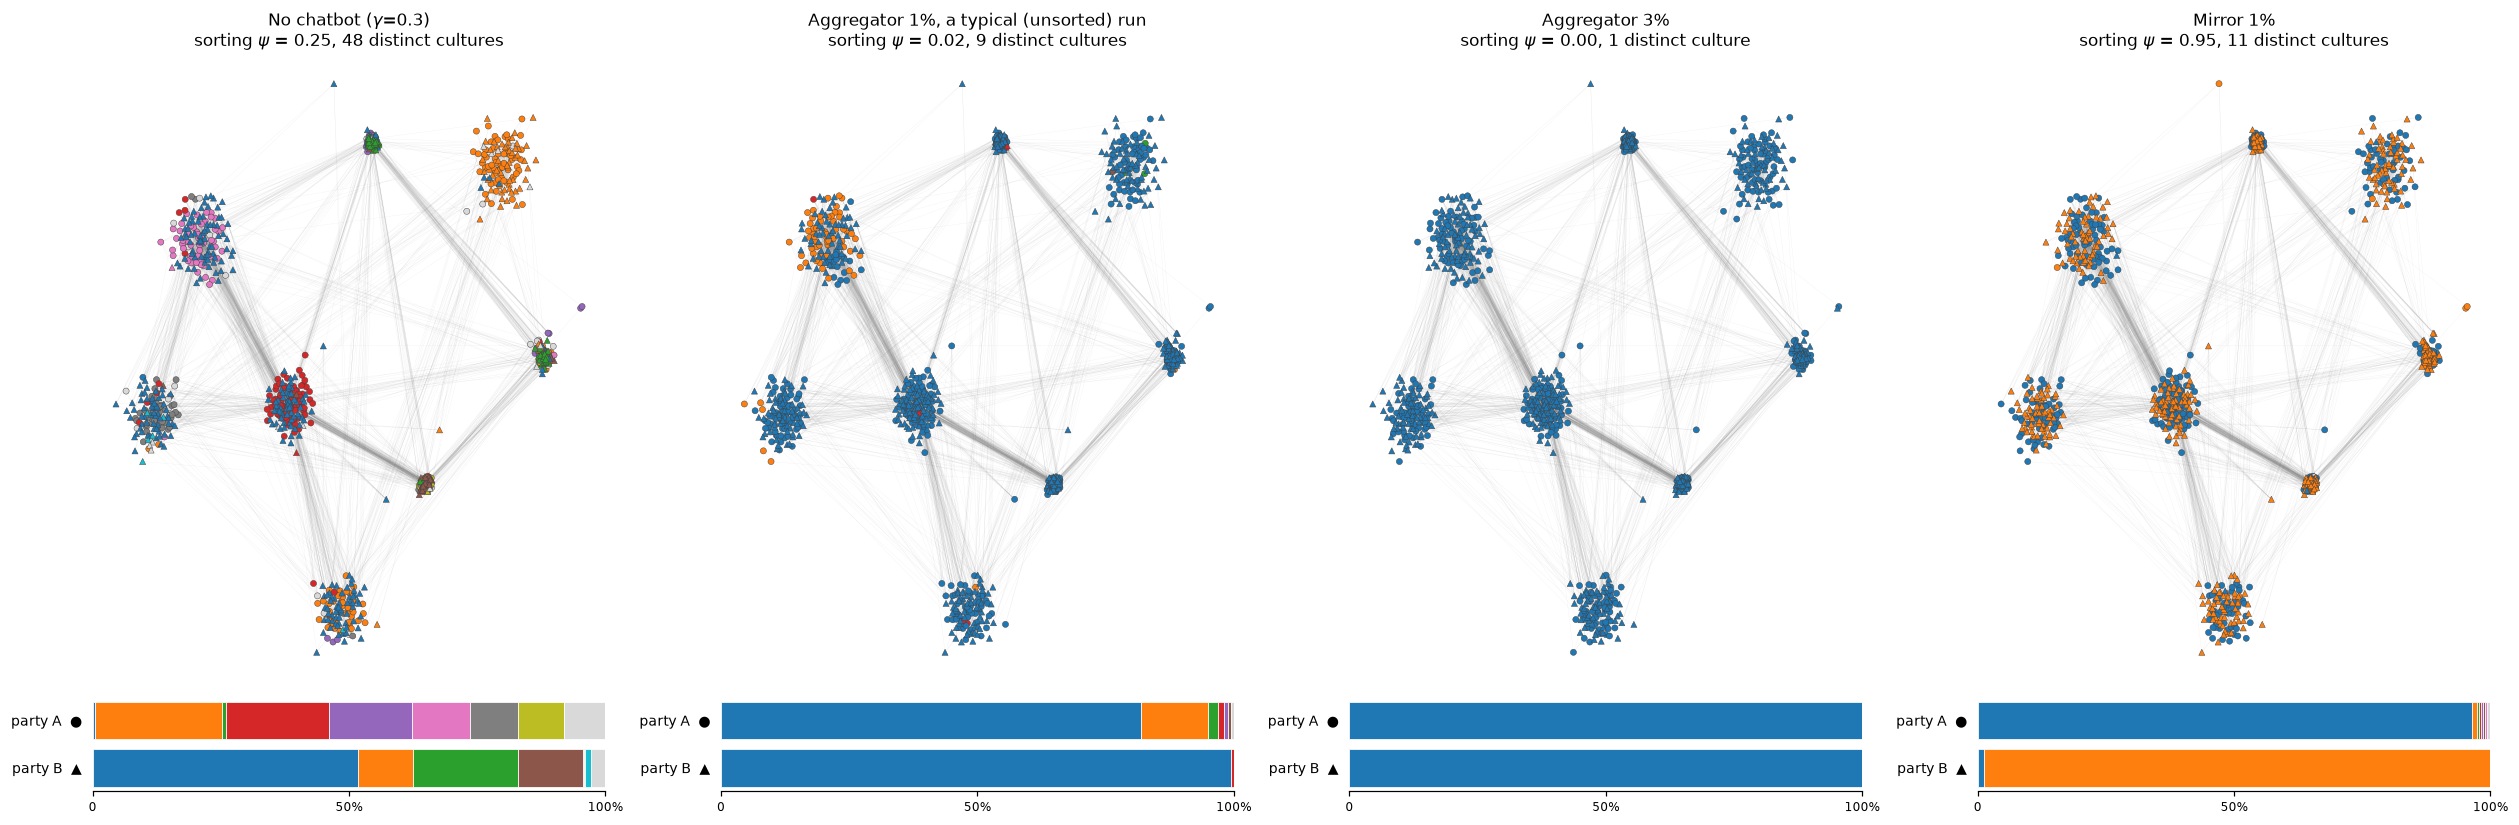

In [11]:
CASES = [('No chatbot ($\\gamma$=0.3)', dict(gamma=0.3, seed=31)),
         ('Aggregator 1%, a typical (unsorted) run', dict(gamma=0.3, alpha=0.01, mode=1, seed=41, want=lambda p: p < 0.1)),
         ('Aggregator 3%', dict(gamma=0.3, alpha=0.03, mode=1, seed=61)),
         ('Mirror 1%', dict(gamma=0.3, alpha=0.01, mode=2, seed=51))]

fig, ax = plt.subplots(2, 4, figsize=(23, 7.6), gridspec_kw={'height_ratios': [6, 0.9]})
for k, (title, kw) in enumerate(CASES):
    party, flex, psi, uniq = end_state(**kw)
    draw_state(ax[0, k], ax[1, k], party, flex, f'{title}\nsorting $\\psi$ = {abs(psi):.2f}, {cultures_word(uniq)}')
plt.tight_layout()
plt.savefig('figures/03b_llm_end_states.png', dpi=150, bbox_inches='tight')
plt.show()

### Findings (§2.3), at a realistic background of $\gamma=0.2$–0.4

Without a chatbot, these societies are partly sorted ($\psi$ = 0.24–0.45).

* **Aggregator: pushes towards one shared culture.** At 0.1–0.3 % of conversations it changes little. At 1 %, 7 of 12 runs at $\gamma=0.3$ end near consensus ($\psi<0.05$), but the rest stay partly sorted, so the mean is 0.13–0.38 with a large spread. From 3 % upward, every run ends in a single culture ($\psi=0$) at every $\gamma$.
* **Mirror: sorts every society, fast.** At 0.3 % of conversations $\psi$ rises to about 0.5–0.57; at 1 % to about 0.75–0.8; from 3 % to about 0.85–0.9, at all three $\gamma$. The effect is largest where strangers alone sort least: at $\gamma=0.2$, $\psi$ goes from 0.24 to 0.79 at 1 %. Diversity falls to 6–9 cultures (roughly one per party plus leftovers), never to one.
* **Interpretation.** The chatbot is the only contact everyone shares, and it always gives the same kind of answer. Whether that answer depends on the user's party decides whether it erases differences altogether (aggregator) or aligns them with party (mirror).

**Caveats.** Instant retraining, perfect party inference for the mirror, full trust and equal adoption all make these effects upper bounds. 12 runs per point.

## 2.4 Points of contention for future work

* **What $\gamma$ is.** Uniformly random strangers, swapped in per conversation, is a crude proxy for internet use. Real online contacts are mostly existing or weak ties, filtered by homophily and by algorithms. A better proxy would draw "strangers" with a distance-decay or homophily-weighted rule, or from a second, online layer of ties.
* **What a tie is, and how many.** The results depend strongly on the mean degree (§2.2c). About 14 rests on Dunbar's sympathy group, but the political discussion network is much smaller (2–3).
* **Party is independent of community.** Real networks show political homophily: communities lean one way, and most ties are within party. Correlating party with community is a natural next step.
* **No negative reaction.** In Törnberg's model people ignore dissimilar others; they are never pushed away. Repulsion (negative influence) would make strangers polarising in a second way.
* **Static network.** Ties never respond to culture. In the feature-driven model ties come from similarity, so the network could be re-drawn as traits change: sorting would then rewire friendships.
* **Chatbot assumptions.** Instant retraining, perfect party inference for the mirror, full trust, equal adoption. Each makes the chatbot's effect an upper bound.
* **Statistics.** 12–16 runs per point, one network realisation, bistable outcomes. Means mix sorted and unsorted runs; shares of sorted runs are reported alongside.